In [2]:
import sys
sys.path.append("../source")

import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

import diffrax as dfx

from core.spacing import LinearSpacing, SpacingExtent, NUM_GHOSTS
from core.grid import Grid
from core.statevector import StateVector
from core.rhsevolution import get_rhs
from matter.scalarmatter import ScalarMatter
from backgrounds.sphericalbackground import FlatSphericalBackground
from bssn.bssnstatevariables import idx_phi, idx_lapse
from bssn.constraintsdiagnostic import get_constraints_diagnostic

In [3]:
from math import isfinite

In [4]:
A = 0.22 # amplitude
r0 = 0
sigma = 1.0

num_points = 401
r_max = 10.0

T = 6.0 # initial maximum time evolution
T_MAX = 24.0 # stop extending unresolved runs at this time
T_EXTENSION_FACTOR = 1.25 # multiply the run time when extending
SUBCRITICAL_FINAL_LAPSE = 0.9 # classify as subcritical if the final lapse is above this

# Provisional subcritical test: require a clear rise from the lapse minimum,
# and reject a substantial drop in the final half time unit.
RECOVERY_WINDOW_TIME = 0.5
RECOVERY_MIN_RISE = 0.05
RECOVERY_MAX_LATE_DROP = 0.03
num_output_times = 101 # number of times to save the output
dt0 = 0.0025

matter = ScalarMatter(a_scalar_mu=0.0)
state_vector = StateVector(matter)

spacing = LinearSpacing(
    num_points=num_points,
    r_max=r_max,
    extent=SpacingExtent.HALF,
)
grid = Grid(spacing, state_vector)
background = FlatSphericalBackground(grid.r)

physical = slice(NUM_GHOSTS, -NUM_GHOSTS)
r_physical = grid.r[physical]
dr = grid.derivs.dx

In [5]:
def scalar_profile(r, amplitude, sigma):
    return amplitude * r**2 * jnp.exp(-(r / sigma)**2)

scalar_profile_dr = jax.grad(scalar_profile, argnums=0)




In [6]:
def solve_psi(r_aux, dr, amplitude, r0, sigma):
    du_dr = jax.vmap(
    scalar_profile_dr,
    in_axes=(0, None, None),)(r_aux, amplitude, sigma)

    source = jnp.pi * du_dr**2
    n = r_aux.size

    main_diag = source * dr**2 - 2.0
    main_diag = main_diag.at[0].add(1.0 - dr / r_aux[0])

    outer_factor = (
        2.0 * dr / r_aux[-1]
        * (1.0 + dr / r_aux[-1])
    )
    main_diag = main_diag.at[-1].add(-outer_factor)

    lower_diag = jnp.zeros_like(r_aux)
    upper_diag = jnp.zeros_like(r_aux)

    upper_diag = upper_diag.at[:-1].set(
        1.0 + dr / r_aux[:-1]
    )
    lower_diag = lower_diag.at[1:].set(
        1.0 - dr / r_aux[1:]
    )
    lower_diag = lower_diag.at[-1].set(2.0)

    rhs = jnp.zeros_like(r_aux)
    rhs = rhs.at[-1].set(-outer_factor)

    psi = jax.lax.linalg.tridiagonal_solve(
        lower_diag,
        main_diag,
        upper_diag,
        rhs[:, None],
    )[:, 0]

    return psi

In [7]:
def make_initial_state(amplitude):
    psi_physical = solve_psi(
        r_physical, dr, amplitude, r0, sigma
    )
    u_physical = scalar_profile(
        r_physical, amplitude, sigma
    )

    state = jnp.zeros((grid.NUM_VARS, grid.N))

    state = state.at[idx_phi, physical].set(jnp.log(psi_physical))
    state = state.at[idx_lapse, physical].set(psi_physical**-2)
    state = state.at[matter.idx_u, physical].set(u_physical)
    state = state.at[matter.idx_v, physical].set(0.0)

    state = grid.fill_boundaries(state)
    return state.reshape(-1)

In [8]:
def evolve(amplitude, t_final=T):
    y0 = make_initial_state(amplitude) # builds state at t0

    def rhs_for_diffrax(t, state, args):
        return get_rhs(t, state, grid, background, matter) # wrapper for Diffrax inputs

    def collapse_condition(t, state, args, **kwargs):
        state_grid = state.reshape(grid.NUM_VARS, grid.N)
        central_lapse = state_grid[idx_lapse, NUM_GHOSTS]
        return central_lapse <= 5e-3 # provisional collapse event

    def save_central_scalar(t, state, args):
        state_grid = state.reshape(grid.NUM_VARS, grid.N)
        return state_grid[matter.idx_u, NUM_GHOSTS]

    def save_central_lapse(t, state, args):
        state_grid = state.reshape(grid.NUM_VARS, grid.N)
        return state_grid[idx_lapse, NUM_GHOSTS]

    save_times = jnp.linspace(0.0, t_final, num_output_times, endpoint=False)
    saveat = dfx.SaveAt(
        subs=[
            # Stream 0: full states at plot output times
            dfx.SubSaveAt(ts=save_times, t1=True),

            # Stream 1: central scalar at solver steps, used for L
            dfx.SubSaveAt(
                t0=True,
                steps=True,
                fn=save_central_scalar,
            ),

            # Stream 2: central lapse at solver steps, used for classification
            dfx.SubSaveAt(
                t0=True,
                steps=True,
                fn=save_central_lapse,
            ),
        ]
    )

    # Keep enough solver steps available when an unresolved run is extended.
    max_steps = max(2000, int(t_final / dt0) + 10)

    solution = dfx.diffeqsolve(
        terms=dfx.ODETerm(rhs_for_diffrax),
        solver=dfx.Dopri5(), # Runge-Kutta solver
        t0=0.0,
        t1=t_final,
        dt0=dt0,
        y0=y0,
        stepsize_controller=dfx.ConstantStepSize(),
        saveat=saveat,
        adjoint=dfx.ForwardMode(),
        event=dfx.Event(collapse_condition),
        max_steps=max_steps,
    )

    return solution


def lapse_recovery_test(lapse_times, lapse_history):
    # Ignore unused inf padding after an event or after the final solver step.
    valid = jnp.isfinite(lapse_times) & jnp.isfinite(lapse_history)
    times = lapse_times[valid]
    lapse = lapse_history[valid]

    if lapse.shape[0] < 3:
        return False, 0.0, 0.0

    minimum_index = int(jnp.argmin(lapse))
    end_time = float(times[-1])
    start_time = end_time - RECOVERY_WINDOW_TIME
    in_window = times >= start_time

    if not bool(jnp.any(in_window)):
        return False, 0.0, 0.0

    first_window_index = int(jnp.argmax(in_window))
    tail_times = times[in_window]
    tail_lapse = lapse[in_window]

    # The lapse minimum must be earlier than this final recovery window.
    if minimum_index >= first_window_index or tail_lapse.shape[0] < 3:
        return False, 0.0, 0.0

    # Measure the total rebound from the minimum. This allows a run to count
    # as recovering even if the lapse has nearly levelled off by the end.
    final_lapse = float(lapse[-1])
    minimum_lapse = float(lapse[minimum_index])
    recovery_rise = final_lapse - minimum_lapse

    # Reject a clear late plunge after an earlier rebound. Small fluctuations
    # near a plateau are allowed.
    late_peak = float(jnp.max(tail_lapse))
    late_drop = late_peak - final_lapse

    changes = jnp.diff(tail_lapse)
    up_fraction = float(jnp.mean(changes > 0.0))
    recovering = (
        recovery_rise >= RECOVERY_MIN_RISE
        and late_drop <= RECOVERY_MAX_LATE_DROP
    )
    return bool(recovering), recovery_rise, up_fraction


# Calculate L, final lapse, and the lapse history.
def run_metrics(amplitude, t_final=T):
    solution = evolve(amplitude, t_final=t_final)

    # Central scalar history, saved at solver steps.
    central_times = solution.ts[1]
    central_u = solution.ys[1]
    valid = jnp.isfinite(central_times) & jnp.isfinite(central_u)
    u_clean = jnp.where(valid, central_u, 0.0)

    changes = jnp.abs(jnp.diff(u_clean))
    valid_pairs = valid[:-1] & valid[1:]
    L = jnp.sum(jnp.where(valid_pairs, changes, 0.0))

    # Full states use stream 0; ignore inf padding after an event.
    state_times = solution.ts[0]
    state_history = solution.ys[0]
    valid_state_times = jnp.isfinite(state_times)
    last_index = jnp.sum(valid_state_times.astype(jnp.int32)) - 1
    final_state = state_history[last_index].reshape(grid.NUM_VARS, grid.N)
    final_lapse = final_state[idx_lapse, NUM_GHOSTS]

    # Lapse stream 2 is auxiliary classification data, not differentiated.
    lapse_times = solution.ts[2]
    lapse_history = solution.ys[2]
    event_fired = solution.result == dfx.RESULTS.event_occurred
    run_successful = solution.result == dfx.RESULTS.successful
        # A successful Diffrax result can still contain nonfinite saved values
    # when using a constant timestep, so check the saved streams directly.
    finite_full_state_at_time = jnp.all(
        jnp.isfinite(state_history), axis=1
    )
    bad_full_state = jnp.any(
        valid_state_times & ~finite_full_state_at_time
    )

    bad_scalar = jnp.any(
        jnp.isfinite(central_times) & ~jnp.isfinite(central_u)
    )
    bad_lapse = jnp.any(
        jnp.isfinite(lapse_times) & ~jnp.isfinite(lapse_history)
    )
    nonfinite_saved_data = bad_full_state | bad_scalar | bad_lapse

    return jnp.stack([L, final_lapse]), (
        event_fired, run_successful, lapse_times, lapse_history,
        nonfinite_saved_data
    )


def evaluate_amplitude(A, t_final=T, check_recovery=False):
    amplitude = jnp.asarray(A, dtype=jnp.float64)

    # Differentiate only L and final_lapse with respect to amplitude.
    def metrics_for_amplitude(amplitude):
        return run_metrics(amplitude, t_final=t_final)

    values, derivatives, aux = jax.jvp(
        metrics_for_amplitude,
        (amplitude,),
        (jnp.ones_like(amplitude),),
        has_aux=True,
    )
    event_fired, run_successful, lapse_times, lapse_history, nonfinite_saved_data = aux

    # Keep only real solver-step values so each run can be plotted later.
    lapse_times_array = np.asarray(lapse_times)
    lapse_history_array = np.asarray(lapse_history)
    valid_lapse = np.isfinite(lapse_times_array) & np.isfinite(lapse_history_array)
    saved_lapse_times = lapse_times_array[valid_lapse].tolist()
    saved_lapse_history = lapse_history_array[valid_lapse].tolist()

    L = float(values[0])
    final_lapse = float(values[1])
    dL_dA = float(derivatives[0])
    if check_recovery:
        recovering, recovery_rise, recovery_up_fraction = lapse_recovery_test(
            lapse_times, lapse_history
        )
    else:
        recovering, recovery_rise, recovery_up_fraction = False, 0.0, 0.0
    if (
        bool(nonfinite_saved_data)
        or not all(isfinite(x) for x in (L, final_lapse))
    ):
        outcome = "failed"
    elif not bool(event_fired) and not bool(run_successful):
        outcome = "failed"
    elif bool(event_fired):
        outcome = "super"  # provisional until AHFinder is added
    elif final_lapse > SUBCRITICAL_FINAL_LAPSE:
        outcome = "sub"
    elif check_recovery and recovering:
        outcome = "sub"
    else:
        outcome = "unresolved"
    
    
    J = float(np.exp(-2.0 * L)) if isfinite(L) else float("nan")
    if isfinite(J) and isfinite(dL_dA):
        dJ_dA = -2.0 * J * dL_dA
    else:
        dJ_dA = float("nan")

    return {
        "A": float(A),
        "T": float(t_final),
        "L": L,
        "dL_dA": dL_dA,
        "J": J,
        "dJ_dA": dJ_dA,
        "gradient_valid": isfinite(dL_dA),
        "final_lapse": final_lapse,
        "recovery_rise": recovery_rise,
        "recovery_up_fraction": recovery_up_fraction,
        "lapse_times": saved_lapse_times,
        "lapse_history": saved_lapse_history,
        "outcome": outcome,
    }


In [9]:
def objective_record(A, t_final):
    record = evaluate_amplitude(
        A,
        t_final=t_final,
        check_recovery=True,
    )

    L = record["L"]
    dL_dA = record["dL_dA"]

    if np.isfinite(L):
        J = float(np.exp(-2.0 * L))
    else:
        J = float("nan")

    if np.isfinite(J) and np.isfinite(dL_dA):
        dJ_dA = -2.0 * J * dL_dA
    else:
        dJ_dA = float("nan")

    record["J"] = J
    record["dJ_dA"] = dJ_dA
    return record


def gradient_descent_from_scratch(
    A_start=0.22,
    t_final=7.5,
    max_iterations=8,
    initial_step_size=0.01,
    max_amplitude_step=0.02,
    max_backtracks=10,
    history=None,
):
    step_size = initial_step_size

    if history:
        history = list(history)
        current = history[-1]
        A = float(current["A"])

        print(
            f"Continuing from A={A:.8f}, "
            f"outcome={current['outcome']}, "
            f"L={current['L']:.6g}, J={current['J']:.6g}"
        )
    else:
        A = float(A_start)
        history = []

        current = objective_record(A, t_final)
        history.append(current)

        print(
            f"Start: A={A:.8f}, outcome={current['outcome']}, "
            f"L={current['L']:.6g}, J={current['J']:.6g}, "
            f"dJ/dA={current['dJ_dA']:.6g}"
        )

    if current["outcome"] == "failed":
        print("Stopping: the starting run failed.")
        return history

    for iteration in range(max_iterations):
        gradient = current["dJ_dA"]

        if not np.isfinite(gradient) or abs(gradient) < 1e-12:
            print("Stopping: the objective gradient is too small or invalid.")
            break

        accepted = False
        trial_step_size = step_size
        trial_max_amplitude_step = max_amplitude_step

        for _ in range(max_backtracks):
            # Gradient descent: A_new = A - step_size * dJ/dA
            change = -trial_step_size * gradient
            change = float(np.clip(
                change,
                -trial_max_amplitude_step,
                trial_max_amplitude_step,
            ))
            A_trial = A + change

            if A_trial <= 0.0 or A_trial == A:
                trial_step_size *= 0.5
                trial_max_amplitude_step *= 0.5
                continue

            trial = objective_record(A_trial, t_final)

            if (
                trial["outcome"] != "failed"
                and np.isfinite(trial["J"])
                and trial["J"] < current["J"]
            ):
                accepted = True
                break

            # Shrink both limits so the next trial tests a smaller amplitude change.
            trial_step_size *= 0.5
            trial_max_amplitude_step *= 0.5

        if not accepted:
            print("Stopping: no tested step lowered J.")
            break

        history.append(trial)
        A = A_trial
        current = trial
        step_size = min(initial_step_size, 1.25 * trial_step_size)

        print(
            f"Step {len(history) - 1}: A={A:.8f}, "
            f"outcome={current['outcome']}, "
            f"L={current['L']:.6g}, J={current['J']:.6g}, "
            f"dJ/dA={current['dJ_dA']:.6g}"
        )

    return history

In [10]:

import pickle

with open("gradient_descent_history.pkl", "rb") as f:
    history = pickle.load(f)

print(f"Loaded {len(history)} runs")
print(history)

Loaded 9 runs
[{'A': 0.22, 'T': 7.5, 'L': 0.5191259875833246, 'dL_dA': 3.0058419286361033, 'J': 0.35407306984153436, 'dJ_dA': -2.1285753582611666, 'gradient_valid': True, 'final_lapse': 0.9483543556844715, 'recovery_rise': 0.38498970153344914, 'recovery_up_fraction': 0.5550000071525574, 'lapse_times': [0.0, 0.0025, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.0175, 0.02, 0.0225, 0.025, 0.0275, 0.03, 0.0325, 0.035, 0.0375, 0.04, 0.0425, 0.045, 0.0475, 0.05, 0.0525, 0.055, 0.0575, 0.06, 0.0625, 0.065, 0.0675, 0.07, 0.0725, 0.075, 0.0775, 0.08, 0.0825, 0.085, 0.08750000000000001, 0.09, 0.0925, 0.095, 0.0975, 0.1, 0.10250000000000001, 0.105, 0.1075, 0.11, 0.1125, 0.115, 0.11750000000000001, 0.12, 0.1225, 0.125, 0.1275, 0.13, 0.1325, 0.135, 0.1375, 0.14, 0.14250000000000002, 0.145, 0.1475, 0.15, 0.1525, 0.155, 0.1575, 0.16, 0.1625, 0.165, 0.1675, 0.17, 0.17250000000000001, 0.17500000000000002, 0.1775, 0.18, 0.1825, 0.185, 0.1875, 0.19, 0.1925, 0.195, 0.1975, 0.2, 0.2025, 0.20500000000000002, 0.207

In [11]:
history = gradient_descent_from_scratch(
    t_final=7.5,
    max_iterations=1,
    initial_step_size=1e-4,
    max_backtracks=4,
    history=history,
)

Continuing from A=0.37324208, outcome=super, L=2.1179, J=0.0144683
Step 9: A=0.37176383, outcome=sub, L=4.698, J=8.30555e-05, dJ/dA=-0.060947


In [12]:
history = gradient_descent_from_scratch(
    t_final=7.5,
    max_iterations=3,
    initial_step_size=1e-4,
    max_backtracks=4,
    history=history,
)

Continuing from A=0.37176383, outcome=sub, L=4.698, J=8.30555e-05
Step 10: A=0.37176535, outcome=sub, L=4.69868, J=8.29431e-05, dJ/dA=-0.055873
Step 11: A=0.37176557, outcome=sub, L=4.6987, J=8.294e-05, dJ/dA=0.0176721
Step 12: A=0.37176548, outcome=sub, L=4.6987, J=8.29394e-05, dJ/dA=-0.000712928


In [16]:
history = gradient_descent_from_scratch(
    t_final=7.5,
    max_iterations=3,
    initial_step_size=1e-4,
    max_backtracks=4,
    history=history,
)

Continuing from A=0.37176548, outcome=sub, L=4.6987, J=8.29394e-05
Stopping: no tested step lowered J.


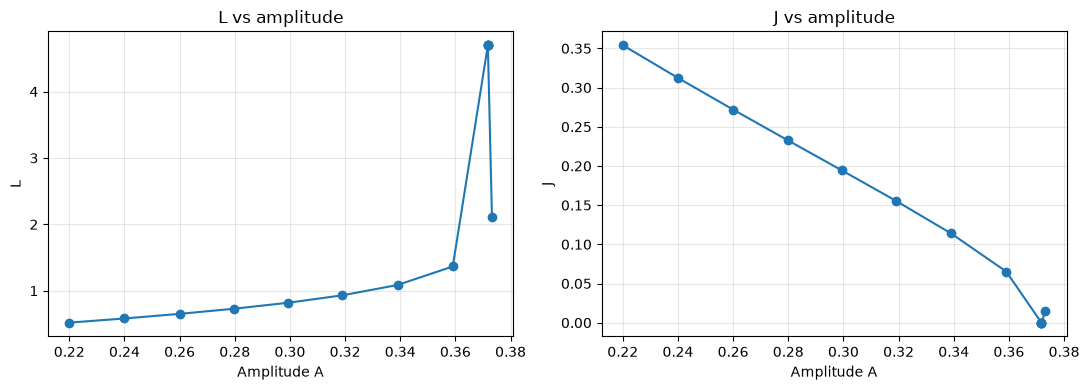

In [13]:
import matplotlib.pyplot as plt
import numpy as np

plot_runs = [
    run for run in history
    if np.isfinite(run["A"])
    and np.isfinite(run["L"])
    and np.isfinite(run["J"])
]
plot_runs = sorted(plot_runs, key=lambda run: run["A"])

A_values = [run["A"] for run in plot_runs]
L_values = [run["L"] for run in plot_runs]
J_values = [run["J"] for run in plot_runs]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(A_values, L_values, "o-")
axes[0].set_xlabel("Amplitude A")
axes[0].set_ylabel("L")
axes[0].set_title("L vs amplitude")
axes[0].grid(True, alpha=0.3)

axes[1].plot(A_values, J_values, "o-")
axes[1].set_xlabel("Amplitude A")
axes[1].set_ylabel("J")
axes[1].set_title("J vs amplitude")
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

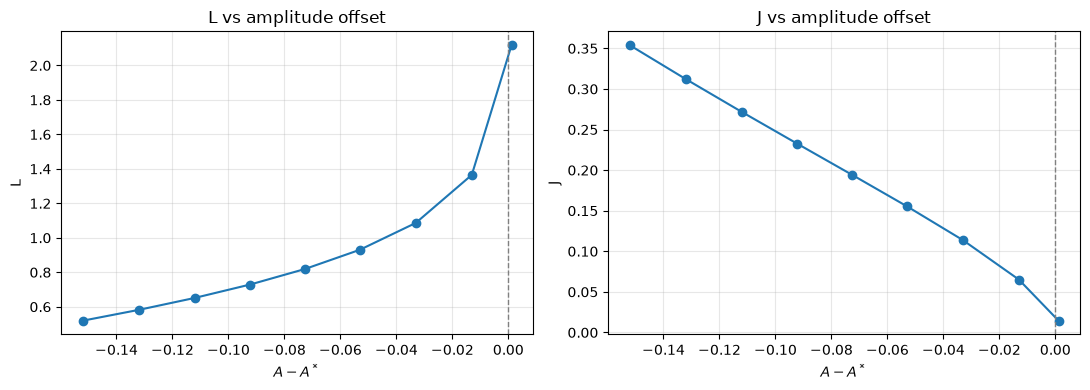

In [24]:
A_star_estimate = 0.372096775  # midpoint of the current sub/super bracket

plot_runs = [
    run for run in history
    if np.isfinite(run["A"])
    and np.isfinite(run["L"])
    and np.isfinite(run["J"])
]

x_values = [run["A"] - A_star_estimate for run in plot_runs]
L_values = [run["L"] for run in plot_runs]
J_values = [run["J"] for run in plot_runs]

# Sort by A - A* so the points are joined from left to right.
ordered = sorted(zip(x_values, L_values, J_values))
x_values, L_values, J_values = zip(*ordered)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(x_values, L_values, "o-")
axes[0].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[0].set_xlabel(r"$A - A^*$")
axes[0].set_ylabel("L")
axes[0].set_title("L vs amplitude offset")
axes[0].grid(True, alpha=0.3)

axes[1].plot(x_values, J_values, "o-")
axes[1].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_xlabel(r"$A - A^*$")
axes[1].set_ylabel("J")
axes[1].set_title("J vs amplitude offset")
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

In [22]:
import pickle

with open("gradient_descent_history.pkl", "wb") as f:
    pickle.dump(history, f)

In [ ]:
history = gradient_descent_from_scratch(
    t_final=7.5,
    max_iterations=9,
    history=history,
)

In [17]:
A_sub = 0.37042082
A_super = 0.37242561

lower = A_sub
upper = A_super
A = 0.5 * (lower + upper)

T_opt = 7.5
step_fraction = 0.1
max_iterations = 5
gd_records = []

for iteration in range(max_iterations):
    record = evaluate_amplitude(
        A,
        t_final=T_opt,
        check_recovery=True,
    )

    L = record["L"]
    dL_dA = record["dL_dA"]

    if np.isfinite(L):
        J = float(np.exp(-2.0 * L))
    else:
        J = float("nan")

    if np.isfinite(J) and np.isfinite(dL_dA):
        dJ_dA = -2.0 * J * dL_dA
    else:
        dJ_dA = float("nan")

    record["J"] = J
    record["dJ_dA"] = dJ_dA
    gd_records.append(record)

    print(
        f"Step {iteration + 1}: A={A:.8f}, "
        f"outcome={record['outcome']}, L={L:.6g}, "
        f"J={J:.6g}, dJ/dA={dJ_dA:.6g}"
    )

    if record["outcome"] == "failed":
        print("Stopping: this run failed.")
        break

    # Update the known bracket from the run's classification.
    if record["outcome"] == "super":
        upper = A
    else:  # sub or unresolved, provisionally treated as sub
        lower = A

    bracket_width = upper - lower
    if bracket_width <= 1e-5:
        print("Stopping: the bracket is sufficiently narrow.")
        break

    # Take a gradient step sized as a fraction of the remaining bracket.
    if np.isfinite(dJ_dA) and abs(dJ_dA) > 1e-12:
        eta = step_fraction * bracket_width / abs(dJ_dA)
        A_next = A - eta * dJ_dA
    else:
        A_next = 0.5 * (lower + upper)

    # Keep the next guess strictly inside the updated bracket.
    if not lower < A_next < upper:
        A_next = 0.5 * (lower + upper)

    A = A_next

Step 1: A=0.37142321, outcome=sub, L=2.84438, J=0.00338381, dJ/dA=-19.0184
Step 2: A=0.37152345, outcome=sub, L=3.20186, J=0.00165539, dJ/dA=-15.6448
Step 3: A=0.37161367, outcome=sub, L=3.74288, J=0.000561022, dJ/dA=-8.70202
Step 4: A=0.37169486, outcome=sub, L=4.40788, J=0.000148377, dJ/dA=-2.10665
Step 5: A=0.37176794, outcome=sub, L=4.69697, J=8.32272e-05, dJ/dA=-0.0929682


In [9]:
runs = []

test_amplitudes = [
    0.37271978,  # previously subcritical
    0.37285883,  # midpoint; previously failed after extension
    0.37299788,  # previously supercritical
]

for A in test_amplitudes:
    record = evaluate_amplitude(A, t_final=T, check_recovery=False)

    J = float(np.exp(-2.0 * record["L"])) if np.isfinite(record["L"]) else float("nan")
    dJ_dA = (
        -2.0 * J * record["dL_dA"]
        if np.isfinite(J) and np.isfinite(record["dL_dA"])
        else float("nan")
    )

    record["J"] = J
    record["dJ_dA"] = dJ_dA
    runs.append(record)

    print(
        f"A={A:.8f}, outcome={record['outcome']}, "
        f"L={record['L']:.6g}, J={J:.6g}, dJ/dA={dJ_dA:.6g}"
    )

A=0.37271978, outcome=unresolved, L=1.72175, J=0.0319529, dJ/dA=14.1239
A=0.37285883, outcome=unresolved, L=1.69442, J=0.0337477, dJ/dA=12.0073
A=0.37299788, outcome=unresolved, L=1.67173, J=0.0353145, dJ/dA=10.6413


In [12]:
extended_runs = []

for original_run in runs:
    record = original_run

    while record["outcome"] == "unresolved" and record["T"] < T_MAX:
        longer_T = min(T_MAX, record["T"] * T_EXTENSION_FACTOR)

        record = evaluate_amplitude(
            record["A"],
            t_final=longer_T,
            check_recovery=True,
        )

        print(
            f"A={record['A']:.8f}, T={record['T']:.3f}, "
            f"outcome={record['outcome']}, "
            f"final lapse={record['final_lapse']:.6g}, "
            f"L={record['L']:.6g}"
        )

    J = float(np.exp(-2.0 * record["L"])) if np.isfinite(record["L"]) else float("nan")
    dJ_dA = (
        -2.0 * J * record["dL_dA"]
        if np.isfinite(J) and np.isfinite(record["dL_dA"])
        else float("nan")
    )
    record["J"] = J
    record["dJ_dA"] = dJ_dA
    extended_runs.append(record)

runs = extended_runs

A=0.37271978, T=7.500, outcome=super, final lapse=0.0049956, L=2.45913
A=0.37285883, T=7.500, outcome=super, final lapse=0.00499542, L=2.46329
A=0.37299788, T=7.500, outcome=super, final lapse=0.00498311, L=2.4604


In [14]:
record = evaluate_amplitude(
    0.37242561,
    t_final=7.5,
    check_recovery=True,
)
print(record["A"], record["T"], record["outcome"], record["L"])

0.37242561 7.5 super 2.4249056623407945


In [16]:
record = evaluate_amplitude(
    0.37042082,
    t_final=7.5,
    check_recovery=True,
)
print(record["A"], record["T"], record["outcome"], record["L"])

0.37042082 7.5 sub 1.922722629354278


In [13]:
[run["T"] for run in runs]

[7.5, 7.5, 7.5]

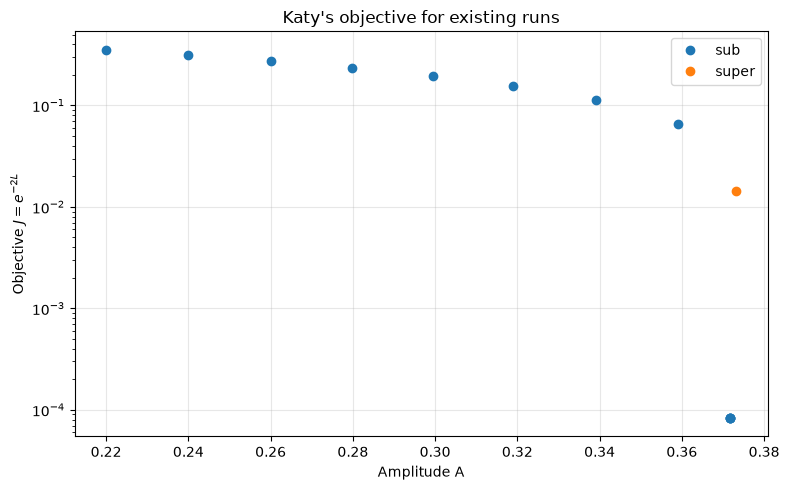

In [15]:
valid_runs = [
    run for run in history
    if run["outcome"] in ("sub", "super", "unresolved")
    and np.isfinite(run["L"])
]

if not valid_runs:
    print("There are no valid runs to plot.")
else:
    fig, ax = plt.subplots(figsize=(8, 5))

    for outcome in ("sub", "super", "unresolved"):
        selected = [run for run in valid_runs if run["outcome"] == outcome]

        if selected:
            amplitudes = [run["A"] for run in selected]
            objectives = [np.exp(-2.0 * run["L"]) for run in selected]
            ax.semilogy(
                amplitudes,
                objectives,
                "o",
                label=outcome,
            )

    ax.set_xlabel("Amplitude A")
    ax.set_ylabel(r"Objective $J = e^{-2L}$")
    ax.set_title("Katy's objective for existing runs")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()

In [7]:
from itertools import combinations
from math import isfinite
from statistics import median


def estimate_b(runs):
    # Use subcritical and unresolved runs as subcritical-side points,
    # provided their gradients are positive and finite.
    usable = [
        run for run in runs
        if run["outcome"] in ("sub", "unresolved")
        and run.get("dL_dA") is not None
        and isfinite(run["dL_dA"])
        and run["dL_dA"] > 0
    ]

    b_values = []

    # Estimate b from pairs using:
    # b = (A2 - A1) / (1/(dL/dA2) - 1/(dL/dA1))
    for run1, run2 in combinations(usable, 2):
        A1, g1 = run1["A"], run1["dL_dA"]
        A2, g2 = run2["A"], run2["dL_dA"]

        denominator = 1.0 / g2 - 1.0 / g1
        if denominator != 0:
            b = (A2 - A1) / denominator
            if isfinite(b) and b < 0:
                b_values.append(b)

    return median(b_values) if b_values else None


def amplitude_already_tried(A, runs):
    return any(float(run["A"]) == float(A) for run in runs)


def midpoint_of_widest_untried_interval(lower, upper, runs):
    tried_inside = sorted({
        float(run["A"])
        for run in runs
        if lower < float(run["A"]) < upper
    })

    points = [lower] + tried_inside + [upper]
    gaps = [
        (points[i + 1] - points[i], points[i], points[i + 1])
        for i in range(len(points) - 1)
    ]

    width, left, right = max(gaps, key=lambda gap: gap[0])
    candidate = 0.5 * (left + right)

    if candidate == left or candidate == right:
        raise ValueError("No distinct amplitude remains inside the bracket.")

    return candidate


def propose_next_amplitude(runs):
    sub = [
        run["A"] for run in runs
        if run["outcome"] in ("sub", "unresolved")
    ]
    supercritical = [
        run["A"] for run in runs
        if run["outcome"] == "super"
    ]

    if not sub or not supercritical:
        raise ValueError("Need at least one subcritical and one supercritical run.")

    lower = max(sub)
    upper = min(supercritical)

    if lower >= upper:
        raise ValueError("The recorded runs do not form a valid bracket.")

    b = estimate_b(runs)

    if b is not None:
        usable_sub = [
            run for run in runs
            if run["outcome"] in ("sub", "unresolved")
            and run.get("dL_dA") is not None
            and isfinite(run["dL_dA"])
            and run["dL_dA"] > 0
        ]

        if usable_sub:
            anchor = max(usable_sub, key=lambda run: abs(run["dL_dA"]))
            candidate = anchor["A"] - b / anchor["dL_dA"]

            if (
                lower < candidate < upper
                and not amplitude_already_tried(candidate, runs)
            ):
                return candidate, f"gradient proposal inside bracket; b={b:.4g}"

    candidate = midpoint_of_widest_untried_interval(lower, upper, runs)
    return candidate, "midpoint of widest untried interval"


def run_next_amplitude(runs, first_A=0.22):
    # Extend the latest unresolved run before proposing a new amplitude.
    if (
        runs
        and runs[-1]["outcome"] == "unresolved"
        and runs[-1]["T"] < T_MAX
    ):
        last = runs[-1]
        longer_T = min(T_MAX, last["T"] * T_EXTENSION_FACTOR)
        record = evaluate_amplitude(
            last["A"], t_final=longer_T, check_recovery=True
        )

        if record["outcome"] == "failed":
            # Keep the earlier finite result and log the failed extension.
            runs.append(record)
        else:
            runs[-1] = record

        print(f"Extended A = {record['A']:.8f} to T = {record['T']:.3f}")
        print(f"Outcome: {record['outcome']}")
        print(f"Final central lapse: {record['final_lapse']:.6g}")
        return record

    usable = [
        run for run in runs
        if run["outcome"] in ("sub", "super", "unresolved")
        and isfinite(run["L"])
        and isfinite(run["final_lapse"])
    ]

    sub = [
        run for run in usable
        if run["outcome"] in ("sub", "unresolved")
    ]
    supercritical = [
        run for run in usable
        if run["outcome"] == "super"
    ]

    if sub and supercritical:
        A_next, reason = propose_next_amplitude(runs)

    elif usable:
        last = usable[-1]
        factor = (
            1.15
            if last["outcome"] in ("sub", "unresolved")
            else 0.87
        )
        A_next = last["A"] * factor

        while amplitude_already_tried(A_next, runs):
            A_next *= factor

        reason = "startup step after latest usable run"

    else:
        A_next = first_A
        while amplitude_already_tried(A_next, runs):
            A_next *= 1.15

        reason = "startup step after failed run"

    record = evaluate_amplitude(A_next, t_final=T)
    runs.append(record)

    print(f"A = {record['A']:.8f}")
    print(f"Outcome: {record['outcome']}")
    print(f"L = {record['L']:.6g}")
    print(f"dL/dA = {record['dL_dA']:.6g}")
    print(f"Final central lapse = {record['final_lapse']:.6g}")
    print(f"Run time T = {record['T']:.3f}")
    print("Proposal rule:", reason)

    return record


In [ ]:
import pickle

def count_valid_points(runs):
    return len({
        float(run["A"])
        for run in runs
        if run["outcome"] in ("sub", "super", "unresolved")
        and isfinite(run["L"])
        and isfinite(run["final_lapse"])
    })


runs = []
target_points = 15
max_failed_attempts = 10
max_total_evaluations = 400
evaluations = 0

while evaluations < max_total_evaluations:
    valid_points = count_valid_points(runs)

    pending_extension = (
        runs
        and runs[-1]["outcome"] == "unresolved"
        and runs[-1]["T"] < T_MAX
    )

    if valid_points >= target_points and not pending_extension:
        break

    record = run_next_amplitude(runs)
    evaluations += 1

    # Save progress after each run/extension in case the overnight run stops.
    with open("runs_checkpoint.pkl", "wb") as checkpoint:
        pickle.dump(runs, checkpoint)

    failed_attempts = sum(
        run["outcome"] == "failed" for run in runs
    )

    print(
        f"Progress: {count_valid_points(runs)}/{target_points} valid points; "
        f"{failed_attempts} failed attempts."
    )

    if failed_attempts >= max_failed_attempts:
        print("Stopping: reached the failed-attempt limit.")
        break

print(f"Finished with {count_valid_points(runs)} valid points.")
 

A = 0.22000000
Outcome: sub
L = 0.519242
dL/dA = 3.00643
Final central lapse = 0.960369
Run time T = 6.000
Proposal rule: startup step after failed run
Progress: 1/40 valid points; 0 failed attempts.
A = 0.25300000
Outcome: sub
L = 0.626101
dL/dA = 3.51607
Final central lapse = 0.944043
Run time T = 6.000
Proposal rule: startup step after latest usable run
Progress: 2/40 valid points; 0 failed attempts.
A = 0.29095000
Outcome: sub
L = 0.778007
dL/dA = 4.61206
Final central lapse = 0.916975
Run time T = 6.000
Proposal rule: startup step after latest usable run
Progress: 3/40 valid points; 0 failed attempts.


In [ ]:
# target_runs = 30
# print("Runs before:", len(runs))

# while len(runs) < target_runs:
#     record = run_next_amplitude(runs)

#     # Keep extending an unresolved run until it is classified
#     # or reaches T_MAX.
#     while record["outcome"] == "unresolved" and record["T"] < T_MAX:
#         record = run_next_amplitude(runs)

#     if record["outcome"] == "failed":
#         print("Stopping because a run failed.")
#         break

# print("Runs after:", len(runs))

Runs before: 5
A = 0.35968694
Outcome: unresolved
L = 1.36898
dL/dA = 21.3017
Final central lapse = 0.773731
Run time T = 6.000
Proposal rule: not enough reliable gradient information; bracket midpoint
Extended A = 0.35968694 to T = 7.500
Outcome: sub
Final central lapse: 0.86643
A = 0.38115470
Outcome: super
L = 1.41361
dL/dA = 8.1476
Final central lapse = 0.00490689
Run time T = 6.000
Proposal rule: gradient proposal inside bracket; b=-0.4813
A = 0.37042082
Outcome: unresolved
L = 1.81328
dL/dA = 89.9915
Final central lapse = 0.615306
Run time T = 6.000
Proposal rule: not enough reliable gradient information; bracket midpoint
Extended A = 0.37042082 to T = 7.500
Outcome: sub
Final central lapse: 0.825151
A = 0.37443041
Outcome: unresolved
L = 1.57683
dL/dA = -69.9267
Final central lapse = 0.0277579
Run time T = 6.000
Proposal rule: gradient proposal inside bracket; b=-0.4449
Extended A = 0.37443041 to T = 7.500
Outcome: unresolved
Final central lapse: 0.00548408
Extended A = 0.374430

In [ ]:
for run in runs:
    print(f"A={run['A']:.8f}, outcome={run['outcome']}")

A=0.22000000, outcome=sub
A=0.25300000, outcome=sub
A=0.29095000, outcome=sub
A=0.33459250, outcome=sub
A=0.38478137, outcome=super
A=0.35968694, outcome=sub
A=0.38115470, outcome=super
A=0.37042082, outcome=sub
A=0.37443041, outcome=super
A=0.37242561, outcome=sub
A=0.37271978, outcome=sub
A=0.37299788, outcome=super
A=0.37285883, outcome=failed


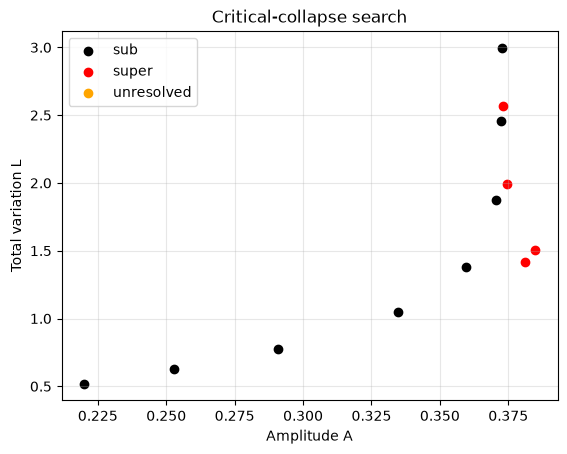

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

for outcome, colour in [
    ("sub", "black"),
    ("super", "red"),
    ("unresolved", "orange"),
]:
    selected = [run for run in runs if run["outcome"] == outcome]
    plt.scatter(
        [run["A"] for run in selected],
        [run["L"] for run in selected],
        color=colour,
        label=outcome,
    )

plt.xlabel("Amplitude A")
plt.ylabel("Total variation L")
plt.title("Critical-collapse search")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:


b = estimate_b(runs)

sub_runs = [
    run for run in runs
    if run["outcome"] == "sub"
    and run.get("dL_dA") is not None
    and isfinite(run["dL_dA"])
    and run["dL_dA"] > 0
]
super_runs = [run for run in runs if run["outcome"] == "super"]

anchor = max(sub_runs, key=lambda run: run["dL_dA"])
A_star_est = anchor["A"] - b / anchor["dL_dA"]

lower = max(run["A"] for run in sub_runs)
upper = min(run["A"] for run in super_runs)

print("Estimated A*:", A_star_est)
print("Current bracket:", lower, "to", upper)

Estimated A*: 0.372997876966855
Current bracket: 0.37271978425743524 to 0.372997876966855


Estimated b: -0.42109671118999026
Estimated A*: 0.372997876966855
Plotted 11 points from 13 run records.


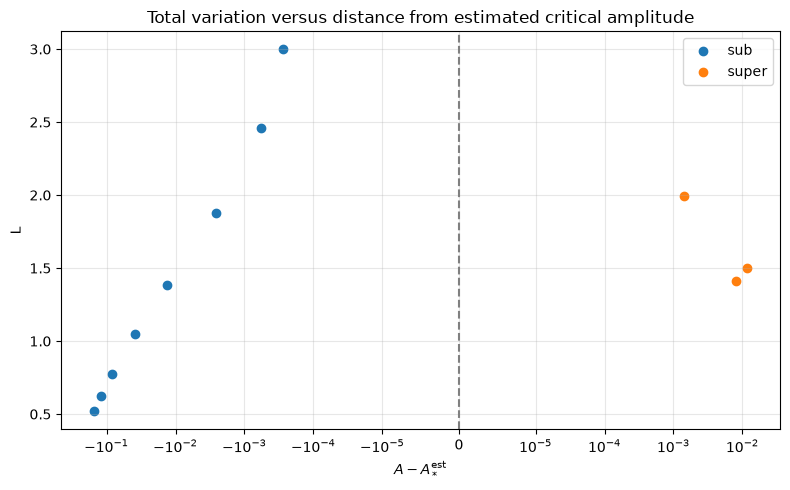

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

b_est = estimate_b(runs)

if b_est is None:
    raise ValueError("There isn't enough gradient data to estimate b.")

usable_sub = [
    run for run in runs
    if run["outcome"] in ("sub", "unresolved")
    and run.get("dL_dA") is not None
    and isfinite(run["dL_dA"])
    and run["dL_dA"] > 0
]

anchor = max(usable_sub, key=lambda run: abs(run["dL_dA"]))
A_star_est = anchor["A"] - b_est / anchor["dL_dA"]

print("Estimated b:", b_est)
print("Estimated A*:", A_star_est)

# Start a fresh figure so points from a previous plot cannot carry over.
fig, ax = plt.subplots(figsize=(8, 5))
points_plotted = 0

for outcome in ("sub", "super", "unresolved"):
    selected = [
        run for run in runs
        if run["outcome"] == outcome
        and np.isfinite(run["L"])
        and abs(run["A"] - A_star_est) > 0
    ]

    if selected:
        distance = np.array([
            run["A"] - A_star_est for run in selected
        ])
        L_values = np.array([run["L"] for run in selected])
        ax.scatter(distance, L_values, label=outcome)
        points_plotted += len(selected)

ax.set_xscale("symlog", linthresh=1e-5)
ax.set_xlabel(r"$A - A_*^{\mathrm{est}}$")
ax.axvline(0, color="gray", linestyle="--")
ax.set_ylabel("L")
ax.set_title("Total variation versus distance from estimated critical amplitude")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
print(f"Plotted {points_plotted} points from {len(runs)} run records.")
plt.show()


In [ ]:
for run in runs:
    print(f"A={run['A']:.8f}, outcome={run['outcome']}")

A=0.22000000, outcome=sub
A=0.25300000, outcome=sub
A=0.29095000, outcome=sub
A=0.33459250, outcome=sub
A=0.38478137, outcome=super
A=0.35968694, outcome=sub
A=0.38115470, outcome=super
A=0.37042082, outcome=sub
A=0.37443041, outcome=super
A=0.37242561, outcome=sub
A=0.37271978, outcome=sub
A=0.37299788, outcome=super
A=0.37285883, outcome=failed


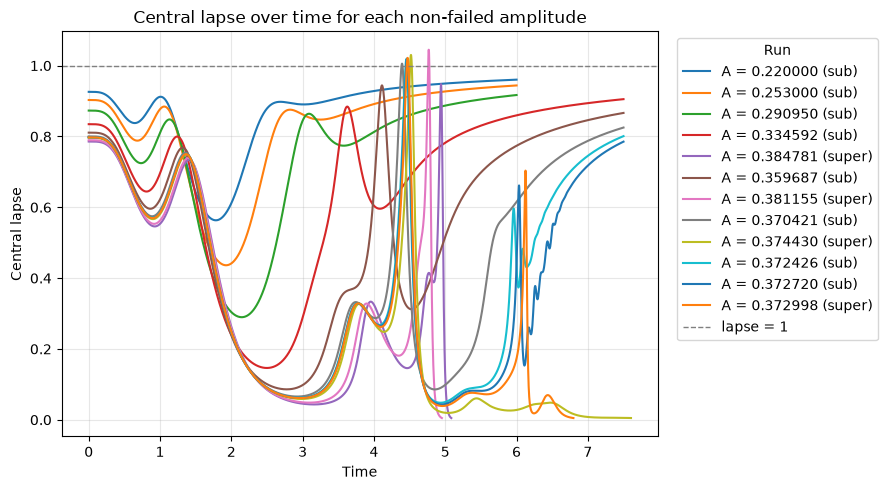

Plotted 12 of 13 runs.


In [ ]:
# Plot the central lapse history for every non-failed run.
import matplotlib.pyplot as plt

plot_runs = [run for run in runs if run.get("outcome") != "failed"]

if not plot_runs:
    print("There are no non-failed runs to plot.")
else:
    fig, ax = plt.subplots(figsize=(9, 5))

    for run in plot_runs:
        ax.plot(
            run["lapse_times"],
            run["lapse_history"],
            label=f"A = {run['A']:.6f} ({run['outcome']})",
        )

    ax.axhline(1.0, color="gray", linestyle="--", linewidth=1, label="lapse = 1")
    ax.set_xlabel("Time")
    ax.set_ylabel("Central lapse")
    ax.set_title("Central lapse over time for each non-failed amplitude")
    ax.grid(True, alpha=0.3)
    ax.legend(title="Run", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    plt.show()

    print(f"Plotted {len(plot_runs)} of {len(runs)} runs.")

In [ ]:
for run in sorted(runs, key=lambda run: run["A"]):
    print(
        f"A={run['A']:.8f}, L={run['L']:.5f}, "
        f"T={run['T']:.2f}, final lapse={run['final_lapse']:.5f}, "
        f"outcome={run['outcome']}"
    )

A=0.22000000, L=0.51924, T=6.00, final lapse=0.96037, outcome=sub
A=0.25300000, L=0.62610, T=6.00, final lapse=0.94404, outcome=sub
A=0.29095000, L=0.77801, T=6.00, final lapse=0.91698, outcome=sub
A=0.33459250, L=1.04657, T=7.50, final lapse=0.90529, outcome=sub
A=0.35968694, L=1.38119, T=7.50, final lapse=0.86643, outcome=sub
A=0.37042082, L=1.87426, T=7.50, final lapse=0.82515, outcome=sub
A=0.37242561, L=2.45856, T=7.50, final lapse=0.80091, outcome=sub
A=0.37271978, L=2.99769, T=7.50, final lapse=0.78536, outcome=sub
A=0.37285883, L=6.80901, T=9.38, final lapse=nan, outcome=failed
A=0.37299788, L=2.56522, T=7.50, final lapse=0.00493, outcome=super
A=0.37443041, L=1.99123, T=9.38, final lapse=0.00500, outcome=super
A=0.38115470, L=1.41361, T=6.00, final lapse=0.00491, outcome=super
A=0.38478137, L=1.50276, T=6.00, final lapse=0.00484, outcome=super


In [ ]:
# A_test = 0.37205123
# T_test = 9.375

# sol_test = evolve(A_test, t_final=T_test)

# print("Result:", sol_test.result)
# print("Solver stats:", sol_test.stats)

# times = np.asarray(sol_test.ts[0])
# states = np.asarray(sol_test.ys[0])
# finite_time = np.isfinite(times)
# finite_state = np.isfinite(states).reshape(len(states), -1).all(axis=1)
# bad = np.flatnonzero(finite_time & ~finite_state)

# if len(bad):
#     print("First saved nonfinite state at t =", times[bad[0]])
# else:
#     print("No nonfinite saved states.")

Result: diffrax._solution.RESULTS<>
Solver stats: {'max_steps': 3760, 'num_accepted_steps': Array(3750, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(3750, dtype=int64, weak_type=True)}
No nonfinite saved states.


In [ ]:
# for A_test in [0.37204123, 0.37206123]:
#     sol_test = evolve(A_test, t_final=9.375)

#     times = np.asarray(sol_test.ts[0])
#     states = np.asarray(sol_test.ys[0])
#     finite_time = np.isfinite(times)
#     finite_state = np.isfinite(states).reshape(len(states), -1).all(axis=1)
#     bad = np.flatnonzero(finite_time & ~finite_state)

#     print(f"A={A_test:.8f}; result={sol_test.result}")
#     if len(bad):
#         print(f"  first nonfinite saved state: t={times[bad[0]]:.6f}")
#     else:
#         print("  no nonfinite saved state")

A=0.37204123; result=diffrax._solution.RESULTS<>
  no nonfinite saved state
A=0.37206123; result=diffrax._solution.RESULTS<>
  no nonfinite saved state


In [ ]:
# test_A = 0.37285883
# test_solution = evolve(test_A, t_final=9.375)

# print("Diffrax result:", test_solution.result)

Diffrax result: diffrax._solution.RESULTS<>


In [ ]:
# import jax

# print("ys type:", type(test_solution.ys))
# print("ys structure:", jax.tree_util.tree_structure(test_solution.ys))
# print("types and shapes:")
# print(jax.tree_util.tree_map(
#     lambda x: (type(x).__name__, getattr(x, "shape", None)),
#     test_solution.ys,
# ))

ys type: <class 'list'>
ys structure: PyTreeDef([*, *, *])
types and shapes:
[('ArrayImpl', (102, 11214)), ('ArrayImpl', (3761,)), ('ArrayImpl', (3761,))]


In [ ]:
# print("ts type:", type(test_solution.ts))
# print(jax.tree_util.tree_map(
#     lambda x: (type(x).__name__, getattr(x, "shape", None)),
#     test_solution.ts,
# ))

ts type: <class 'list'>
[('ArrayImpl', (102,)), ('ArrayImpl', (3761,)), ('ArrayImpl', (3761,))]


In [ ]:
# import numpy as np
# import jax

# ys_parts = jax.tree_util.tree_leaves(test_solution.ys)
# ts_parts = jax.tree_util.tree_leaves(test_solution.ts)

# for i, (ts_part, ys_part) in enumerate(zip(ts_parts, ys_parts)):
#     times = np.asarray(ts_part)
#     values = np.asarray(ys_part)

#     finite_at_time = np.isfinite(values).reshape(len(times), -1).all(axis=1)
#     bad = np.flatnonzero(~finite_at_time)

#     if len(bad):
#         print(f"Series {i}: first nonfinite value at t = {times[bad[0]]}")
#     else:
#         print(f"Series {i}: all saved values finite")

Series 0: first nonfinite value at t = 7.611386138613861
Series 1: first nonfinite value at t = 7.5225
Series 2: first nonfinite value at t = 7.5225


In [ ]:
# first_failed=0.37205123
# testing_failed_solution = evolve(first_failed, t_final=9.375)
# print("Diffrax result for first failed amplitude:", testing_failed_solution.result)


In [ ]:
# test_A = 0.37285883
# test_solution = evolve(test_A, t_final=9.375)
# print("Diffrax result:", test_solution.result)

Diffrax result: diffrax._solution.RESULTS<Terminating differential equation solve because an event occurred.>


In [ ]:
# print("Stopped at t =", test_solution.t1)

Stopped at t = 9.375
